# Aula 5 - Regressão linear e logística com a Olist

**Business Intelligence e Análise Preditiva - Centro Universitário SENAC - Prof. Pedro Ernesto da Silva Souza**

Perguntas de negócio:
1. **Quantos dias um pedido vai levar para chegar?** (regressão - alvo `dias_entrega`)
2. **Qual a probabilidade de o pedido atrasar?** (classificação - alvo `atrasado`)

Decisões apoiadas: prazo prometido ao cliente por rota e priorização de despacho dos pedidos com maior risco de atraso.

Base: `olist_modelagem.csv` - 96.470 pedidos entregues (2016 a 2018), um por linha, com atributos conhecidos no momento da compra.

Como usar: execute as células na ordem (`Shift + Enter`). Os trechos marcados com **TODO** devem ser completados por você. Dupla: ______________________

## 1. Configuração

In [24]:
# Configuração: bibliotecas (todas já instaladas no Colab)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn as sk
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
SEMENTE = 42
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

pandas 2.2.2 | scikit-learn 1.5.1


## 2. Entendimento dos dados (CRISP-DM, etapa 2)

Carregue a base. No Colab, a célula abaixo pede o upload do arquivo `olist_modelagem.csv`.

In [2]:
import os
CAMINHO = "../aula02/Dataset Olist/olist_modelagem.csv"
if not os.path.exists(CAMINHO):
    try:
        from google.colab import files  # só existe no Colab
        print("Selecione o arquivo olist_modelagem.csv (pacote Olist)")
        files.upload()
    except ImportError:
        pass
df = pd.read_csv(CAMINHO)
print(df.shape)
df.head()

(96470, 28)


,order_id,order_purchase_timestamp,ano_compra,mes_compra,dia_semana_compra,hora_compra,customer_state,seller_state,mesmo_estado,n_itens,n_vendedores,preco_total,frete_total,peso_total_g,volume_total_cm3,fotos_media,descricao_media,categoria_principal,categoria_principal_en,payment_type,parcelas,valor_pago,dias_aprovacao,dias_estimados,dias_entrega,atrasado,review_score,avaliacao_baixa
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,2017,10,0,10,SP,SP,1,1,1,29.99,8.72,500.0,1976.0,4.0,268.0,utilidades_domesticas,housewares,voucher,1.0,38.71,0.007431,15.544063,8.436574,0,4,0.0
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,2018,7,1,20,BA,SP,0,1,1,118.70,22.76,400.0,4693.0,1.0,178.0,perfumaria,perfumery,boleto,1.0,141.46,1.279745,19.137766,13.782037,0,4,0.0
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,2018,8,2,8,GO,SP,0,1,1,159.90,19.22,420.0,9576.0,1.0,232.0,automotivo,auto,credit_card,3.0,179.12,0.011505,26.639711,9.394213,0,5,0.0
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,2017,11,5,19,RN,MG,0,1,1,45.00,27.20,450.0,6000.0,3.0,468.0,pet_shop,pet_shop,credit_card,1.0,72.20,0.012419,26.188819,13.208750,0,5,0.0
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,2018,2,1,21,SP,SP,1,1,1,19.90,8.72,250.0,11475.0,4.0,316.0,papelaria,stationery,credit_card,1.0,28.62,0.042940,12.112049,2.873877,0,5,0.0


In [3]:
# Dicionário resumido das colunas (completo em DICIONARIO_DE_DADOS_OLIST.docx)
print(df.dtypes.to_string())
print("\nValores ausentes por coluna (só as que têm):")
print(df.isna().sum()[df.isna().sum() > 0].to_string())

order_id                     object
order_purchase_timestamp     object
ano_compra                    int64
mes_compra                    int64
dia_semana_compra             int64
hora_compra                   int64
customer_state               object
seller_state                 object
mesmo_estado                  int64
n_itens                       int64
n_vendedores                  int64
preco_total                 float64
frete_total                 float64
peso_total_g                float64
volume_total_cm3            float64
fotos_media                 float64
descricao_media             float64
categoria_principal          object
categoria_principal_en       object
payment_type                 object
parcelas                    float64
valor_pago                  float64
dias_aprovacao              float64
dias_estimados              float64
dias_entrega                float64
atrasado                      int64
review_score                  int64
avaliacao_baixa             

In [4]:
# Os dois alvos
print(df["dias_entrega"].describe().round(2).to_string())
print(f"\nTaxa de atraso (prevalência): {df['atrasado'].mean():.2%}  ({df['atrasado'].sum()} de {len(df)} pedidos)")

count    96470.00
mean        12.56
std          9.55
min          0.53
25%          6.77
50%         10.22
75%         15.72
max        209.63

Taxa de atraso (prevalência): 8.11%  (7826 de 96470 pedidos)


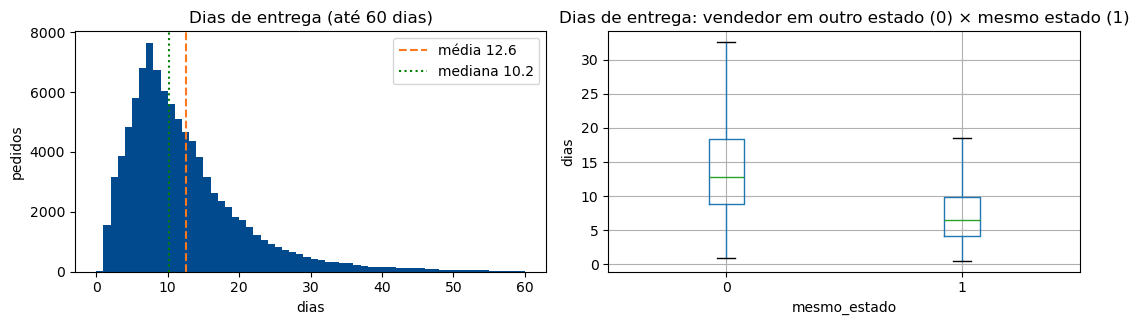

              dias_entrega  atrasado
mesmo_estado                        
0                   15.150     0.093
1                    7.945     0.061


In [12]:
# Distribuição do tempo de entrega
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(df["dias_entrega"], bins=60, range=(0, 60), color="#014A8E")
ax[0].set_title("Dias de entrega (até 60 dias)"); ax[0].set_xlabel("dias"); ax[0].set_ylabel("pedidos")
ax[0].axvline(df["dias_entrega"].mean(), color="#FF781D", linestyle="--", label=f"média {df['dias_entrega'].mean():.1f}")
ax[0].axvline(df["dias_entrega"].median(), color="green", linestyle=":", label=f"mediana {df['dias_entrega'].median():.1f}")
ax[0].legend()
df.boxplot(column="dias_entrega", by="mesmo_estado", ax=ax[1], showfliers=False)
ax[1].set_title("Dias de entrega: vendedor em outro estado (0) × mesmo estado (1)"); ax[1].set_xlabel("mesmo_estado"); ax[1].set_ylabel("dias")
plt.suptitle(""); plt.tight_layout(); plt.show()
print(df.groupby("mesmo_estado")[["dias_entrega", "atrasado"]].mean().round(3))

In [6]:
# Atraso e tempo médio por estado do cliente
por_uf = df.groupby("customer_state").agg(pedidos=("order_id", "size"), dias_medios=("dias_entrega", "mean"),
                                           taxa_atraso=("atrasado", "mean")).sort_values("dias_medios")
print(por_uf.round(3).to_string())

                pedidos  dias_medios  taxa_atraso
customer_state                                   
SP                40494        8.761        0.059
PR                 4923       11.992        0.050
MG                11354       12.009        0.056
DF                 2080       12.968        0.071
SC                 3546       14.955        0.098
RS                 5344       15.300        0.071
RJ                12350       15.309        0.135
GO                 1957       15.606        0.082
MS                  701       15.618        0.116
ES                 1995       15.789        0.122
TO                  274       17.658        0.128
MT                  886       18.056        0.068
PE                 1593       18.448        0.108
RN                  474       19.278        0.108
BA                 3256       19.335        0.140
RO                  243       19.372        0.029
PI                  476       19.457        0.160
PB                  517       20.427        0.110


In [7]:
# Correlação das variáveis numéricas com o tempo de entrega
numericas_todas = ["dias_entrega", "dias_estimados", "mesmo_estado", "frete_total", "peso_total_g", "volume_total_cm3",
                   "n_itens", "preco_total", "dias_aprovacao", "parcelas", "hora_compra", "dia_semana_compra", "mes_compra"]
print(df[numericas_todas].corr()["dias_entrega"].drop("dias_entrega").sort_values().round(3).to_string())

mesmo_estado        -0.362
mes_compra          -0.055
n_itens             -0.019
hora_compra          0.002
dia_semana_compra    0.029
parcelas             0.052
preco_total          0.056
volume_total_cm3     0.063
peso_total_g         0.071
dias_aprovacao       0.080
frete_total          0.167
dias_estimados       0.384


**Anote três fatos sobre os dados** (edite esta célula):

1. 
2. 
3. 

## 3. Preparação dos dados (etapa 3)

Modelo base: sete variáveis conhecidas no momento da compra. Variáveis que só existem depois da entrega (`dias_entrega`, `atrasado`, `review_score`, `avaliacao_baixa`) **não** entram em X: seria vazamento.

O `ColumnTransformer` aplica, nas numéricas, imputação pela mediana e padronização; nas categóricas, imputação pela moda e one-hot (categorias com menos de 50 pedidos são agrupadas em `infrequent_sklearn`). Tudo dentro de um `Pipeline`, ajustado só no treino.

In [8]:
numericas = ["dias_estimados", "mesmo_estado", "frete_total", "peso_total_g", "n_itens", "dias_aprovacao"]
categoricas = ["customer_state"]
variaveis = numericas + categoricas

def criar_preprocessador(numericas, categoricas):
    return ColumnTransformer([
        ("num", Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())]), numericas),
        ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=50, sparse_output=False))]), categoricas),
    ])

preprocessador = criar_preprocessador(numericas, categoricas)

# Regressão: alvo dias_entrega
X = df[variaveis]
y = df["dias_entrega"]
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=SEMENTE)
print("treino:", X_treino.shape, "| teste:", X_teste.shape)
print("colunas após o pré-processamento:", preprocessador.fit(X_treino).transform(X_treino.head()).shape[1])

treino: (77176, 7) | teste: (19294, 7)
colunas após o pré-processamento: 32


## 4. Regressão linear (etapas 4 e 5)

Linha de base: prever a média do treino para todos os pedidos. Qualquer modelo útil precisa superar isso.

In [9]:
previsao_base = np.full(len(y_teste), y_treino.mean())
print(f"Linha de base (média = {y_treino.mean():.2f} dias): RMSE {np.sqrt(mean_squared_error(y_teste, previsao_base)):.2f} | MAE {mean_absolute_error(y_teste, previsao_base):.2f}")

Linha de base (média = 12.59 dias): RMSE 9.31 | MAE 6.43


### TODO 1 - treinar a regressão linear

Crie o `Pipeline` (pré-processador + `LinearRegression()`), ajuste no treino e gere as previsões no teste.

In [29]:
# TODO 1: complete as três linhas abaixo
modelo_linear = Pipeline([("pre", criar_preprocessador(numericas, categoricas)), ("reg", LinearRegression())])   # qual estimador?
modelo_linear.fit(X_treino, y_treino)                                                                           # ajustar no treino
previsao = modelo_linear.predict(X_teste)                                                                 # prever no teste
print(previsao[:5].round(2))

[ 7.2   9.9  12.82  7.36  7.65]


### TODO 2 - métricas de regressão

Calcule MAE, RMSE e R² no conjunto de teste e compare com a linha de base.

In [ ]:
# TODO 2: use mean_absolute_error, mean_squared_error (com np.sqrt) e r2_score
mae = mean_absolute_error(y_teste, previsao_base)
rmse = np.sqrt(mean_squared_error(y_teste, previsao_base))
r2 = ...
print(f"Regressão linear (modelo base): MAE {mae:.2f} dias | RMSE {rmse:.2f} dias | R² {r2:.3f}")

In [ ]:
# Real × previsto e resíduos (amostra de 3.000 pedidos para o gráfico)
amostra = np.random.RandomState(SEMENTE).choice(len(y_teste), 3000, replace=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(y_teste.values[amostra], previsao[amostra], s=6, alpha=0.4, color="#014A8E")
ax[0].plot([0, 60], [0, 60], color="#FF781D"); ax[0].set_xlim(0, 60); ax[0].set_ylim(0, 60)
ax[0].set_xlabel("dias reais"); ax[0].set_ylabel("dias previstos"); ax[0].set_title("Real × previsto")
residuos = y_teste.values - previsao
ax[1].hist(residuos, bins=80, range=(-30, 60), color="#595959"); ax[1].set_title("Resíduos (real − previsto)"); ax[1].set_xlabel("dias")
plt.tight_layout(); plt.show()
print(f"Resíduo médio {residuos.mean():.2f} | 5% dos pedidos têm erro acima de {np.percentile(np.abs(residuos), 95):.1f} dias")

In [ ]:
# Coeficientes (variáveis padronizadas: comparáveis entre si)
nomes = modelo_linear.named_steps["pre"].get_feature_names_out()
coef = pd.Series(modelo_linear.named_steps["reg"].coef_, index=[n.split("__")[1] for n in nomes]).sort_values()
print(f"Intercepto: {modelo_linear.named_steps['reg'].intercept_:.2f} dias")
print("\nCinco coeficientes mais negativos (reduzem o prazo):"); print(coef.head(5).round(2).to_string())
print("\nCinco coeficientes mais positivos (aumentam o prazo):"); print(coef.tail(5).round(2).to_string())

## 5. Regressão logística: probabilidade de atraso (etapas 4 e 5)

Mesmas variáveis; alvo `atrasado` (0/1). A divisão é **estratificada** para manter 8,1% de atrasos nos dois conjuntos.

In [31]:
y_c = df["atrasado"]
X_treino_c, X_teste_c, y_treino_c, y_teste_c = train_test_split(X, y_c, test_size=0.2, random_state=SEMENTE, stratify=y_c)
print(f"treino: {len(y_treino_c)} pedidos ({y_treino_c.mean():.2%} atrasados) | teste: {len(y_teste_c)} ({y_teste_c.mean():.2%})")

def avaliar_classificador(y_real, prob, limiar=0.5, nome="modelo"):
    pred = (prob >= limiar).astype(int)
    print(f"{nome} (limiar {limiar}): acurácia {accuracy_score(y_real, pred):.3f} | precisão {precision_score(y_real, pred, zero_division=0):.3f} | "
          f"recall {recall_score(y_real, pred):.3f} | F1 {f1_score(y_real, pred):.3f} | AUC {roc_auc_score(y_real, prob):.3f}")
    return pred

treino: 77176 pedidos (8.11% atrasados) | teste: 19294 (8.11%)


In [32]:
# Primeira tentativa: sem tratar o desbalanceamento
modelo_log0 = Pipeline([("pre", criar_preprocessador(numericas, categoricas)), ("clf", LogisticRegression(max_iter=2000))])
modelo_log0.fit(X_treino_c, y_treino_c)
prob0 = modelo_log0.predict_proba(X_teste_c)[:, 1]
pred0 = avaliar_classificador(y_teste_c, prob0, 0.5, "Logística sem balanceamento")
print("Matriz de confusão [[VN, FP], [FN, VP]]:", confusion_matrix(y_teste_c, pred0).tolist())
print(f"Atrasos reais no teste: {y_teste_c.sum()} | atrasos previstos: {pred0.sum()}")

Logística sem balanceamento (limiar 0.5): acurácia 0.919 | precisão 1.000 | recall 0.001 | F1 0.003 | AUC 0.686
Matriz de confusão [[VN, FP], [FN, VP]]: [[17729, 0], [1563, 2]]
Atrasos reais no teste: 1565 | atrasos previstos: 2


A acurácia de 91,9% é a **armadilha da acurácia**: o modelo quase nunca prevê atraso. 

### TODO 3 - balancear as classes

Treine a logística com `class_weight="balanced"` e obtenha as probabilidades no teste.

Logística balanceada (limiar 0.5): acurácia 0.647 | precisão 0.135 | recall 0.623 | F1 0.222 | AUC 0.688
Matriz de confusão [[VN, FP], [FN, VP]]: [[11500, 6229], [590, 975]]


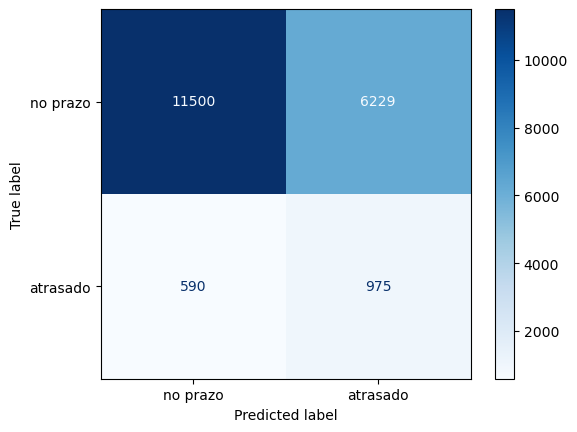

In [34]:
# TODO 3: complete com class_weight="balanced" e predict_proba
modelo_log = Pipeline([("pre", criar_preprocessador(numericas, categoricas)),
                       ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))])
modelo_log.fit(X_treino_c, y_treino_c)
prob = modelo_log.predict_proba(X_teste_c)[:, 1]
pred = avaliar_classificador(y_teste_c, prob, 0.5, "Logística balanceada")
mc = confusion_matrix(y_teste_c, pred)
print("Matriz de confusão [[VN, FP], [FN, VP]]:", mc.tolist())
ConfusionMatrixDisplay(mc, display_labels=["no prazo", "atrasado"]).plot(cmap="Blues"); plt.show()

### TODO 4 - escolher o limiar

A tabela e a curva ROC abaixo mostram o efeito do limiar. Escolha um limiar para a Olist e justifique na célula de texto seguinte.

 limiar  precisão  recall    F1  atrasos previstos
    0.3     0.093   0.950 0.170              15930
    0.4     0.109   0.813 0.192              11693
    0.5     0.135   0.623 0.222               7204
    0.6     0.170   0.429 0.243               3964
    0.7     0.206   0.208 0.207               1582


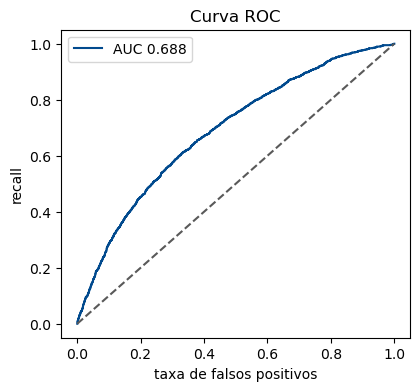

In [35]:
linhas = []
for limiar in [0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (prob >= limiar).astype(int)
    linhas.append({"limiar": limiar, "precisão": precision_score(y_teste_c, p, zero_division=0), "recall": recall_score(y_teste_c, p),
                   "F1": f1_score(y_teste_c, p), "atrasos previstos": int(p.sum())})
print(pd.DataFrame(linhas).round(3).to_string(index=False))

fpr, tpr, _ = roc_curve(y_teste_c, prob)
plt.figure(figsize=(4.5, 4)); plt.plot(fpr, tpr, color="#014A8E", label=f"AUC {roc_auc_score(y_teste_c, prob):.3f}")
plt.plot([0, 1], [0, 1], "--", color="#595959"); plt.xlabel("taxa de falsos positivos"); plt.ylabel("recall"); plt.title("Curva ROC"); plt.legend(); plt.show()

**TODO 4 - Limiar escolhido e justificativa** (edite esta célula): limiar = ____ porque ...

In [36]:
# Razões de chance (odds ratios): efeito multiplicativo de cada variável na chance de atraso
nomes = modelo_log.named_steps["pre"].get_feature_names_out()
odds = pd.Series(np.exp(modelo_log.named_steps["clf"].coef_[0]), index=[n.split("__")[1] for n in nomes]).sort_values()
print("Reduzem a chance de atraso:"); print(odds.head(6).round(2).to_string())
print("\nAumentam a chance de atraso:"); print(odds.tail(6).round(2).to_string())

Reduzem a chance de atraso:
customer_state_PR    0.28
customer_state_MG    0.33
customer_state_SP    0.33
customer_state_DF    0.41
dias_estimados       0.46
customer_state_RO    0.50

Aumentam a chance de atraso:
customer_state_AP                    1.79
customer_state_CE                    1.81
customer_state_MA                    2.19
customer_state_PA                    2.34
customer_state_AL                    3.70
customer_state_infrequent_sklearn    4.51


## 6. Conclusões de negócio

Escreva três conclusões (edite esta célula): o que a operação da Olist deveria fazer com estes resultados e quais são os limites dos modelos.

1.
2.
3.

## 7. Atividade extra - TODO 5: novas variáveis

Inclua as variáveis abaixo, treine de novo os dois modelos e preencha a tabela comparativa. Comente em três linhas: o ganho compensa? O que mais poderia melhorar o modelo?

In [ ]:
# TODO 5 (atividade extra): complete as listas, treine os dois modelos ampliados e monte a tabela comparativa
numericas_ext = numericas + [...]      # mes_compra, hora_compra, dia_semana_compra, preco_total, volume_total_cm3, fotos_media, descricao_media, parcelas, valor_pago, n_vendedores
categoricas_ext = categoricas + [...]  # seller_state, categoria_principal, payment_type
X_ext = df[numericas_ext + categoricas_ext]

# Regressão ampliada (mesma divisão: random_state=SEMENTE)
Xtr, Xte, ytr, yte = train_test_split(X_ext, y, test_size=0.2, random_state=SEMENTE)
reg_ext = ...
p_ext = ...
# Logística ampliada (estratificada)
Xtr_c, Xte_c, ytr_c, yte_c = train_test_split(X_ext, y_c, test_size=0.2, random_state=SEMENTE, stratify=y_c)
log_ext = ...
prob_ext = ...
pred_ext = (prob_ext >= 0.5).astype(int)

comparativo = pd.DataFrame({
    "modelo base": [mae, rmse, r2, precision_score(y_teste_c, pred), recall_score(y_teste_c, pred), f1_score(y_teste_c, pred), roc_auc_score(y_teste_c, prob)],
    "modelo ampliado": [...],
}, index=["MAE (dias)", "RMSE (dias)", "R²", "precisão (0,5)", "recall (0,5)", "F1 (0,5)", "AUC"])
print(comparativo.round(3).to_string())

**Comentário (três linhas):** 

---
Referências: Müller e Guido, *Introdução ao machine learning com Python*, cap. 2; Sharda, Delen e Turban, cap. 4; documentação do scikit-learn (modelos lineares e métricas).